# S2 · Peer-nomination survey

After the game, each child answered nine questions of the form *“select
2 to 5 classmates who…”*. Questions 3 (best friends), 4 (most popular
and well-known) and 5 (not popular or well-known) are the ones used in
the main analysis. Code: `code/si/S2_nomination_survey.R`.

In [ ]:
here::i_am("notebooks/si/S2_nomination_survey.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads <- read_csv(here("data", "generated", "analysis_dyads.csv"), show_col_types = FALSE)

question_labels <- c(nom_q3 = "Best friends (Q3)",
                     nom_q4 = "Most popular & well-known (Q4)",
                     nom_q5 = "Not popular or well-known (Q5)")

## Table S3. Nominations sent and the limit of five

How many classmates each child named, and how many hit the limit of five
(few) or named fewer than two (more common for “not popular”).

In [ ]:
# How many classmates each child named in each question
out_nominations <- dyads %>%
  group_by(sender_id) %>%
  summarise(across(c(nom_q3, nom_q4, nom_q5), sum)) %>%
  pivot_longer(-sender_id, names_to = "question", values_to = "nominations") %>%
  mutate(question = question_labels[question])

table_s3 <- out_nominations %>%
  group_by(question) %>%
  summarise(mean      = mean(nominations),
            sd        = sd(nominations),
            median    = median(nominations),
            at_cap    = 100 * mean(nominations == 5),
            below_min = 100 * mean(nominations < 2),
            above_cap = sum(nominations > 5))

table_s3

question,mean,sd,median,at_cap,below_min,above_cap
Best friends (Q3),3.012806,1.306635,3,13.736903,13.50407,0
Most popular & well-known (Q4),2.641443,1.204868,2,7.916182,15.59953,0
Not popular or well-known (Q5),2.222352,1.310941,2,4.423749,31.89756,0


## Figure S1. Distribution of nominations sent

In [ ]:
# Figure S1: how many classmates each child named in each question, with the
# median as a dotted line
panel_letters <- setNames(c("A. ", "B. ", "C. "), question_labels)

bars <- out_nominations %>%
  count(question, nominations) %>%
  group_by(question) %>%
  mutate(percent = 100 * n / sum(n),
         at_cap  = nominations == 5,                 # the limit of five
         panel   = paste0(panel_letters[question], question)) %>%
  ungroup()

medians <- out_nominations %>%
  group_by(question) %>%
  summarise(median = median(nominations)) %>%
  mutate(panel = paste0(panel_letters[question], question))

A basic version first, written here only to show how the figure is
built:

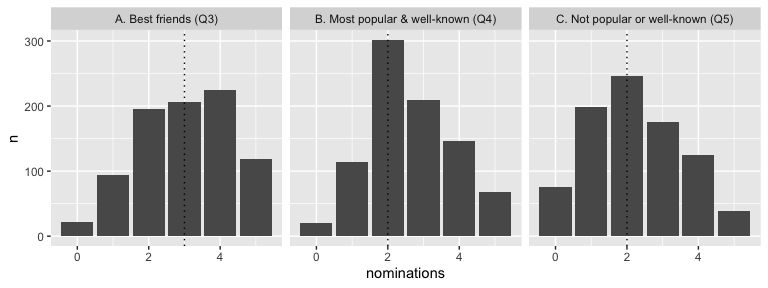

In [ ]:
ggplot(bars, aes(nominations, n)) +
  geom_col() +
  geom_vline(data = medians, aes(xintercept = median), linetype = "dotted") +
  facet_wrap(~ panel)

The figure as in the SI, with its colors, labels and legends (code from
the script):

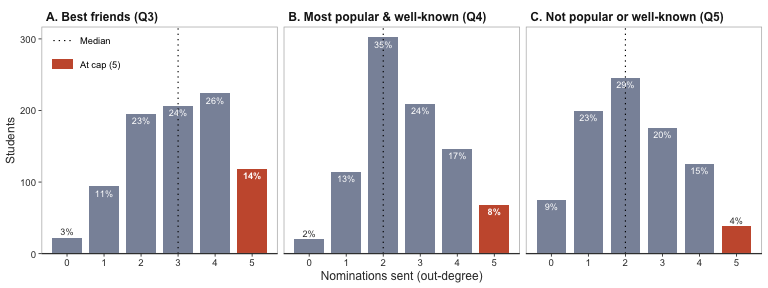

In [ ]:
# Bars: children by number of classmates named; the bar at the limit of five
# in orange, with the share of children on each bar
figure_s1 <- ggplot(bars, aes(nominations, n, fill = at_cap)) +
  geom_col(width = 0.8) +
  geom_vline(data = medians, aes(xintercept = median, linetype = "Median"),
             inherit.aes = FALSE, linewidth = 0.4, key_glyph = "path") +
  # percentages inside the bars (white), or above the shortest ones (dark)
  geom_text(data = filter(bars, n >= 40),
            aes(label = paste0(round(percent), "%"), fontface = if_else(at_cap, "bold", "plain")),
            vjust = 1.5, color = "white", size = 2.4) +
  geom_text(data = filter(bars, n < 40), aes(label = paste0(round(percent), "%")),
            vjust = -0.5, color = color_text, size = 2.4) +
  facet_wrap(~ panel) +
  scale_fill_manual(values = c(`FALSE` = color_slate, `TRUE` = color_highlight),
                    breaks = "TRUE", labels = "At cap (5)", name = NULL) +
  scale_linetype_manual(values = c(Median = "dotted"), name = NULL) +
  scale_x_continuous(breaks = 0:5) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.05))) +
  labs(x = "Nominations sent (out-degree)", y = "Students") +
  theme_si_frame(base_size = 9) +
  theme(strip.text = element_text(face = "bold", hjust = 0, size = 9),
        panel.border = element_rect(color = "grey70", fill = NA),
        axis.line.x = element_line(color = "grey20"),
        legend.position = c(0.005, 0.99), legend.justification = c(0, 1),
        legend.spacing.y = unit(0, "pt"), legend.key.height = unit(0.3, "cm"),
        legend.text = element_text(size = 7), legend.background = element_blank())
figure_s1

## Table S4. Consistency of the two popularity questions

A “conflict” is naming the same classmate as both most popular and not
popular. Each conflict involves two nominations, which is why its share
is computed as $2 \times$ conflicts over all popularity nominations.

In [ ]:
# Table S4: the same classmate named as "most popular" (Q4) and as
# "not popular" (Q5) by the same child. Each conflict involves two
# nominations, so its share of all popularity nominations is
# 2 x conflicts / (Q4 nominations + Q5 nominations).

conflicts <- dyads %>% filter(nom_q4 == 1, nom_q5 == 1)

table_s4 <- tibble(
  conflicting_pairs     = nrow(conflicts),
  share_of_nominations  = 100 * 2 * nrow(conflicts) / (sum(dyads$nom_q4) + sum(dyads$nom_q5)),
  children_with_conflict = n_distinct(conflicts$sender_id),
  classes_with_conflict  = n_distinct(conflicts$class_id)
)

table_s4

conflicting_pairs,share_of_nominations,children_with_conflict,classes_with_conflict
121,5.792245,70,30


In [ ]:
save_table(table_s3, "S2_table_s3_nomination_cap")
save_table(table_s4, "S2_table_s4_consistency")
ggsave(here("output", "figures", "si", "S2_figure_s1_nominations.pdf"), figure_s1, width = 8, height = 3)
ggsave(here("output", "figures", "si", "S2_figure_s1_nominations.png"), figure_s1, width = 8, height = 3, dpi = 300)